### Importing libraries

In [1]:
import numpy as np
import pandas as pd
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem.porter import PorterStemmer
from sklearn.feature_extraction.text import CountVectorizer
import pickle
import matplotlib.pyplot as plt
import joblib

### Importing dataset

In [2]:
dataset = pd.read_csv('fresh_reviews.tsv', delimiter = '\t', quoting = 3)
dataset.head()

,Review
0,Spend your money elsewhere.
1,Their regular toasted bread was equally satisf...
2,The Buffet at Bellagio was far from what I ant...
3,"And the drinks are WEAK, people!"
4,-My order was not correct.


### Data cleaning

In [3]:
nltk.download('stopwords')

ps = PorterStemmer()

all_stopwords = stopwords.words('english')
all_stopwords.remove('not')

[nltk_data] Downloading package stopwords to C:\Users\Renu
[nltk_data]     R\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [4]:
corpus = []

for i in range(len(dataset)): 
    review = re.sub('[^a-zA-Z]',' ',dataset['Review'][i]) #d ropping special characters and numbers
    review = review.lower() # converting to lower case
    review = review.split()
    review = [ps.stem(word) for word in review if not word in set(all_stopwords)]
    review = ' '.join(review)
    corpus.append(review)

### Data transformation

In [5]:
cvFile = 'sentiment_analysis_bow'
cv = pickle.load(open(cvFile, "rb"))

c:\Users\Renu R\anaconda3\Lib\site-packages\sklearn\base.py:380: InconsistentVersionWarning: Trying to unpickle estimator CountVectorizer from version 1.7.1 when using version 1.6.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


In [6]:
X_fresh = cv.transform(corpus).toarray()
X_fresh.shape

(100, 1287)

### Predictions (via sentiment classifier)

In [7]:
classifier = joblib.load('sentiment_analysis_model')

with open('model_info', 'r') as f:
    model_name = f.read()

print("Model used for prediction:", model_name)

Model used for prediction: Linear SVM


c:\Users\Renu R\anaconda3\Lib\site-packages\sklearn\base.py:380: InconsistentVersionWarning: Trying to unpickle estimator LinearSVC from version 1.7.1 when using version 1.6.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


In [8]:
Y_pred= classifier.predict(X_fresh)
print(Y_pred)

[0 1 1 0 0 1 1 1 0 1 1 0 0 1 0 1 0 1 0 0 0 0 1 0 0 0 0 1 1 1 1 0 0 0 1 0 1
 0 0 1 0 0 0 0 0 0 0 0 0 0 0 1 1 0 0 0 0 0 0 0 0 1 1 0 0 0 1 0 0 1 0 0 0 1
 0 1 1 0 0 0 0 0 0 0 0 1 0 0 1 0 0 0 0 0 0 0 1 0 1 1]


In [9]:
dataset['predicted_label'] = Y_pred.tolist()
dataset.head()

,Review,predicted_label
0,Spend your money elsewhere.,0
1,Their regular toasted bread was equally satisf...,1
2,The Buffet at Bellagio was far from what I ant...,1
3,"And the drinks are WEAK, people!",0
4,-My order was not correct.,0


In [10]:
# Aggregate sentiment results

sentiment_counts = dataset['predicted_label'].value_counts()

negative_count = sentiment_counts.get(0, 0)
positive_count = sentiment_counts.get(1, 0)

total_reviews = len(dataset)

positive_percentage = (positive_count / total_reviews) * 100
negative_percentage = (negative_count / total_reviews) * 100

print("Total Reviews:", total_reviews)
print("Positive Reviews:", positive_count)
print("Negative Reviews:", negative_count)
print("Positive Sentiment:", round(positive_percentage, 2), "%")
print("Negative Sentiment:", round(negative_percentage, 2), "%")

Total Reviews: 100
Positive Reviews: 32
Negative Reviews: 68
Positive Sentiment: 32.0 %
Negative Sentiment: 68.0 %


In [11]:
# -----------------------------------------
# FINDING COMMON ISSUES IN NEGATIVE REVIEWS
# -----------------------------------------

# Select only negative reviews
negative_reviews = dataset[dataset['predicted_label'] == 0].copy()

print("Total negative reviews:", len(negative_reviews))

Total negative reviews: 68


In [12]:
issues = {
    'Food Quality': [
        'food', 'taste', 'tasteless', 'bland', 'flavor', 'flavour',
        'dish', 'meal', 'menu', 'pizza', 'burger', 'chicken',
        'meat', 'rice', 'sauce', 'dessert'
    ],

    'Service': [
        'service', 'waiter', 'waitress', 'server', 'staff',
        'employee', 'rude', 'unfriendly', 'slow', 'poor service'
    ],

    'Waiting Time': [
        'wait', 'waiting', 'slow', 'delay', 'minutes', 'long',
        'forever', 'late'
    ],

    'Price / Value': [
        'price', 'expensive', 'cost', 'cheap', 'value',
        'money', 'worth', 'overpriced'
    ],

    'Ambience': [
        'ambience', 'ambiance', 'atmosphere', 'environment',
        'decor', 'seating', 'music', 'noise', 'crowded'
    ],

    'Drinks': [
        'drink', 'drinks', 'coffee', 'wine', 'beer',
        'cocktail', 'juice', 'beverage'
    ],

    'Cleanliness': [
        'clean', 'dirty', 'hygiene', 'messy', 'bathroom',
        'toilet', 'smell'
    ]
}

In [13]:
issue_results = []

for issue, keywords in issues.items():

    pattern = '|'.join(
        r'\b' + re.escape(keyword) + r'\b'
        for keyword in keywords
    )

    matches = negative_reviews['Review'].str.lower().str.contains(
        pattern,
        regex=True,
        na=False
    )

    count = matches.sum()

    percentage = (count / len(negative_reviews)) * 100

    issue_results.append({
        'Issue': issue,
        'Negative Reviews': count,
        'Percentage of Negative Reviews': round(percentage, 2)
    })

issue_summary = pd.DataFrame(issue_results)

issue_summary = issue_summary.sort_values(
    by='Negative Reviews',
    ascending=False
)

issue_summary


,Issue,Negative Reviews,Percentage of Negative Reviews
0,Food Quality,17,25.00
1,Service,7,10.29
2,Waiting Time,6,8.82
3,Price / Value,4,5.88
4,Ambience,2,2.94
5,Drinks,1,1.47
6,Cleanliness,1,1.47


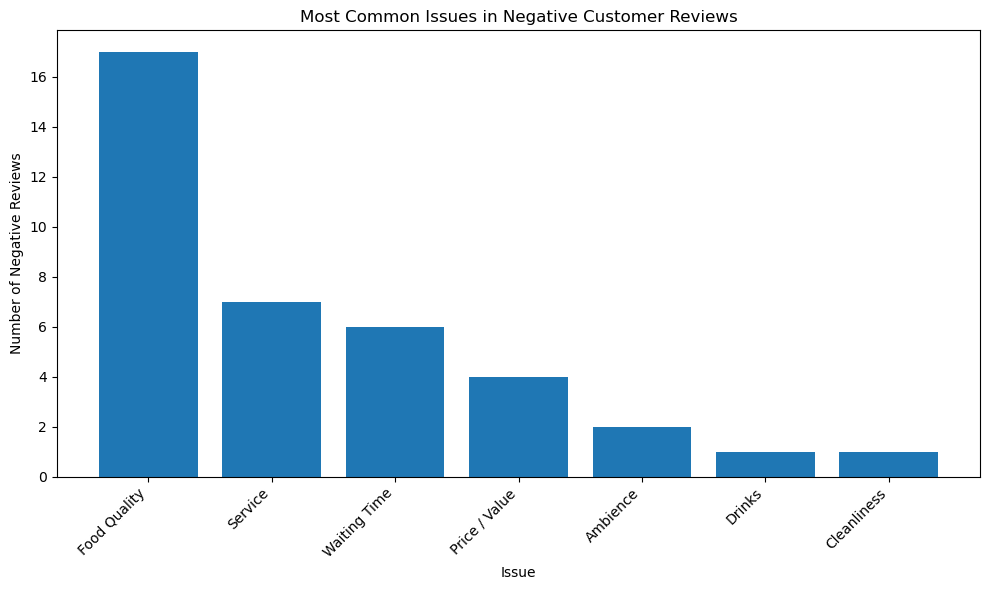

In [14]:
plt.figure(figsize=(10, 6))

plt.bar(
    issue_summary['Issue'],
    issue_summary['Negative Reviews']
)

plt.title('Most Common Issues in Negative Customer Reviews')
plt.xlabel('Issue')
plt.ylabel('Number of Negative Reviews')

plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [15]:
dataset.to_csv('predicted_reviews.csv', index=False)